In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install category_encoders
!pip install xgboost
!pip install lightgbm
!pip install imblearn
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.7/85.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.9/232.9 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.9/253.9 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.7/291.7 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.4/238.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 73.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 105.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 103.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 M

In [3]:
# 📦 Data Handling
import pandas as pd
import numpy as np
from collections import Counter
import time
import warnings

# 🧼 Preprocessing
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
import category_encoders as ce
from imblearn.over_sampling import SMOTE

# 🔍 Model Selection
from sklearn.model_selection import train_test_split

# 📊 Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, auc, precision_score, recall_score, f1_score, precision_recall_curve
)

# 🤖 Machine Learning Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.multiclass import OneVsRestClassifier

# 📉 Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 🔬 Deep Learning with TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input, Dense, Dropout, BatchNormalization, ReLU, Add
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import callbacks


In [4]:
# Load dataset (change filename accordingly)
df = pd.read_csv("/content/drive/MyDrive/Project-rev-2/merged_CSVs.csv")

# Check unique values in the label column
print(df['label'].unique())

<ipython-input-4-7636f6959031>:2: DtypeWarning: Columns (3,5,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267

['Benign' 'label' 'Attack' 'Suspicious']


label
Benign        413199
Attack        228469
Suspicious     59106
label              2
Name: count, dtype: int64


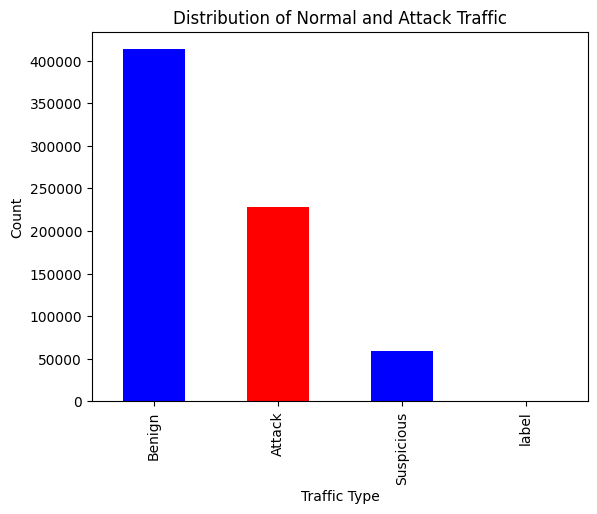

In [5]:
# Count occurrences of each class
print(df['label'].value_counts())

# Plot distribution
df['label'].value_counts().plot(kind='bar', color=['blue', 'red'])
plt.xlabel("Traffic Type")
plt.ylabel("Count")
plt.title("Distribution of Normal and Attack Traffic")
plt.show()

In [6]:
null_count = df.isnull().sum()
print("Null values after preprocessing:\n", df.isnull().sum())

Null values after preprocessing:
 flow_id                                     0
timestamp                                   2
src_ip                                      0
src_port                                    0
dst_ip                                      0
                                        ...  
median_fwd_payload_bytes_delta_len          0
skewness_fwd_payload_bytes_delta_len    80738
cov_fwd_payload_bytes_delta_len         80150
label                                       0
activity                                    0
Length: 324, dtype: int64


In [7]:
# Count total missing values in each column
missing_values_per_column = df.isnull().sum()

# Count total number of columns with at least one missing value
columns_with_missing = missing_values_per_column[missing_values_per_column > 0].count()

# Count total number of rows with at least one missing value
rows_with_missing = df.isnull().any(axis=1).sum()

print(f"Total columns with missing values: {columns_with_missing}")
print(f"Total rows with missing values: {rows_with_missing}")

Total columns with missing values: 42
Total rows with missing values: 544974


In [8]:
missing_values_per_column = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values_per_column / len(df)) * 100

# Combine both count and percentage into a DataFrame
missing_data = pd.DataFrame({
    'Missing Values': missing_values_per_column,
    'Percentage (%)': missing_percentage
})

# Filter out columns that have missing values
missing_data = missing_data[missing_data['Missing Values'] > 0]

# Display the result
print("Columns with missing values:\n", missing_data)

Columns with missing values:
                                       Missing Values  Percentage (%)
timestamp                                          2        0.000285
payload_bytes_skewness                        540271       77.096105
payload_bytes_cov                             540111       77.073273
fwd_payload_bytes_skewness                    476027       67.928553
fwd_payload_bytes_cov                         475285       67.822671
bwd_payload_bytes_skewness                    196913       28.099279
bwd_payload_bytes_cov                         196675       28.065316
skewness_header_bytes                         456723       65.173893
fwd_skewness_header_bytes                     477282       68.107641
bwd_skewness_header_bytes                     175973       25.111162
active_skewness                                  362        0.051657
idle_skewness                                    359        0.051229
packets_IAT_skewness                          449922       64.203397
pack

In [9]:
# Handling 'timestamp' column (forward-fill)
if 'timestamp' in df.columns:
    df['timestamp'] = df['timestamp'].ffill()

# List of numeric columns with NaN
num_cols_with_nan = [
    "payload_bytes_skewness", "payload_bytes_cov", "fwd_payload_bytes_skewness",
    "fwd_payload_bytes_cov", "bwd_payload_bytes_skewness", "bwd_payload_bytes_cov",
    "skewness_header_bytes", "fwd_skewness_header_bytes", "bwd_skewness_header_bytes",
    "active_skewness", "idle_skewness", "packets_IAT_skewness", "packets_IAT_cov",
    "fwd_packets_IAT_skewness", "fwd_packets_IAT_cov", "bwd_packets_IAT_skewness",
    "bwd_packets_IAT_cov", "skewness_packets_delta_time", "cov_packets_delta_time",
    "skewness_bwd_packets_delta_time", "cov_bwd_packets_delta_time",
    "skewness_fwd_packets_delta_time", "cov_fwd_packets_delta_time",
    "skewness_packets_delta_len", "cov_packets_delta_len", "skewness_bwd_packets_delta_len",
    "cov_bwd_packets_delta_len", "skewness_fwd_packets_delta_len", "cov_fwd_packets_delta_len",
    "skewness_header_bytes_delta_len", "cov_header_bytes_delta_len",
    "skewness_bwd_header_bytes_delta_len", "cov_bwd_header_bytes_delta_len",
    "skewness_fwd_header_bytes_delta_len", "cov_fwd_header_bytes_delta_len",
    "skewness_payload_bytes_delta_len", "cov_payload_bytes_delta_len",
    "skewness_bwd_payload_bytes_delta_len", "cov_bwd_payload_bytes_delta_len",
    "skewness_fwd_payload_bytes_delta_len", "cov_fwd_payload_bytes_delta_len"
]

# Ensure numeric columns
df[num_cols_with_nan] = df[num_cols_with_nan].apply(pd.to_numeric, errors='coerce')

# Replace Inf and -Inf with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Cap extreme values (optional: limits values to 99th percentile)
df[num_cols_with_nan] = df[num_cols_with_nan].clip(lower=df[num_cols_with_nan].quantile(0.01),
                                                    upper=df[num_cols_with_nan].quantile(0.99),
                                                    axis=1)

# Apply mean imputation for missing values
mean_imputer = SimpleImputer(strategy='mean')
df[num_cols_with_nan] = mean_imputer.fit_transform(df[num_cols_with_nan])

# Save the processed dataset
df.to_csv("processed_dataset.csv", index=False)

print("Missing values and infinite values handled successfully!")

Missing values and infinite values handled successfully!


In [10]:
null_count = df.isnull().sum()
print(f"Null values in 'column_name': {null_count}")

Null values in 'column_name': flow_id                                 0
timestamp                               0
src_ip                                  0
src_port                                0
dst_ip                                  0
                                       ..
median_fwd_payload_bytes_delta_len      0
skewness_fwd_payload_bytes_delta_len    0
cov_fwd_payload_bytes_delta_len         0
label                                   0
activity                                0
Length: 324, dtype: int64


In [11]:
# Count duplicate rows
duplicate_rows = df.duplicated().sum()

if duplicate_rows > 0:
    print(f"⚠️ Found {duplicate_rows} duplicate rows. Removing them now...")
    df = df.drop_duplicates()
    print("✅ Duplicate rows removed!")
else:
    print("✅ No duplicate rows found!")

⚠️ Found 323 duplicate rows. Removing them now...
✅ Duplicate rows removed!


In [12]:
if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    df['timestamp'] = df['timestamp'].astype('int64') // 10**9  # Convert to seconds
    print("✅ Timestamp converted to numeric format!")

✅ Timestamp converted to numeric format!


In [13]:
# Cap all numeric features at 1st and 99th percentile
for col in df.select_dtypes(include=[np.number]).columns:
    lower = df[col].quantile(0.01)
    upper = df[col].quantile(0.99)
    df[col] = df[col].clip(lower, upper)

print("✅ Outliers capped using 1st and 99th percentiles.")

✅ Outliers capped using 1st and 99th percentiles.


In [14]:
scaler = StandardScaler()
df[df.select_dtypes(include=[np.number]).columns] = scaler.fit_transform(df.select_dtypes(include=[np.number]))

print("✅ Features normalized using StandardScaler!")

✅ Features normalized using StandardScaler!


In [15]:
# Identify categorical columns
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Categorical columns: {cat_cols}")

# Apply Ordinal Encoding (less RAM than get_dummies)
ordinal_encoder = ce.OrdinalEncoder(cols=cat_cols)
df[cat_cols] = ordinal_encoder.fit_transform(df[cat_cols])

print("✅ Categorical columns encoded using OrdinalEncoder!")


Categorical columns: ['flow_id', 'src_ip', 'src_port', 'dst_ip', 'dst_port', 'protocol', 'duration', 'packets_count', 'fwd_packets_count', 'bwd_packets_count', 'total_payload_bytes', 'fwd_total_payload_bytes', 'bwd_total_payload_bytes', 'payload_bytes_max', 'payload_bytes_min', 'payload_bytes_mean', 'payload_bytes_std', 'payload_bytes_variance', 'payload_bytes_median', 'payload_bytes_mode', 'fwd_payload_bytes_max', 'fwd_payload_bytes_min', 'fwd_payload_bytes_mean', 'fwd_payload_bytes_std', 'fwd_payload_bytes_variance', 'fwd_payload_bytes_median', 'fwd_payload_bytes_mode', 'bwd_payload_bytes_max', 'bwd_payload_bytes_min', 'bwd_payload_bytes_mean', 'bwd_payload_bytes_std', 'bwd_payload_bytes_variance', 'bwd_payload_bytes_median', 'bwd_payload_bytes_mode', 'total_header_bytes', 'max_header_bytes', 'min_header_bytes', 'mean_header_bytes', 'std_header_bytes', 'median_header_bytes', 'cov_header_bytes', 'mode_header_bytes', 'variance_header_bytes', 'fwd_total_header_bytes', 'fwd_max_header_by

In [16]:
warnings.filterwarnings("ignore")

#  Feature-label split ===
X = df.drop(columns=["label"])
y = df["label"]

#  Remove under-represented classes (optional but recommended) ===
label_counts = y.value_counts()
valid_labels = label_counts[label_counts >= 2].index
X = X[y.isin(valid_labels)]
y = y[y.isin(valid_labels)]

#  Drop leaky columns BEFORE train-test split
leaky_cols = ['flow_id', 'timestamp', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'activity']
X = X.drop(columns=[col for col in leaky_cols if col in X.columns])

#  Drop highly correlated features
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.95)]
X = X.drop(columns=to_drop)

# Split before SMOTE to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
# === STEP 4: Apply SMOTE to balance training set ===
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"✅ SMOTE applied: Class distribution after resampling:\n{pd.Series(y_train_smote).value_counts()}")

# === STEP 5: Encode labels ===
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train_smote)
y_test_encoded = le.transform(y_test)

print("✅ Label Mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print("\n📊 Training class distribution:\n", pd.Series(y_train_smote).value_counts())
print("\n📊 Test class distribution:\n", y_test.value_counts())

#Convert to NumPy arrays
X_train_np = X_train_smote.to_numpy().astype('float32')
X_test_np = X_test.to_numpy().astype('float32')
y_train_np = y_train_encoded.astype('int')
y_test_np = y_test_encoded.astype('int')


✅ SMOTE applied: Class distribution after resampling:
label
1    289042
3    289042
4    289042
Name: count, dtype: int64
✅ Label Mapping: {np.int64(1): np.int64(0), np.int64(3): np.int64(1), np.int64(4): np.int64(2)}

📊 Training class distribution:
 label
1    289042
3    289042
4    289042
Name: count, dtype: int64

📊 Test class distribution:
 label
1    123876
3     68535
4     17725
Name: count, dtype: int64



🔄 Training: Random Forest
✅ Accuracy: 0.9609
📋 Classification Report:
               precision    recall  f1-score   support

           1       0.98      0.98      0.98    123876
           3       0.96      0.95      0.96     68535
           4       0.85      0.89      0.87     17725

    accuracy                           0.96    210136
   macro avg       0.93      0.94      0.93    210136
weighted avg       0.96      0.96      0.96    210136



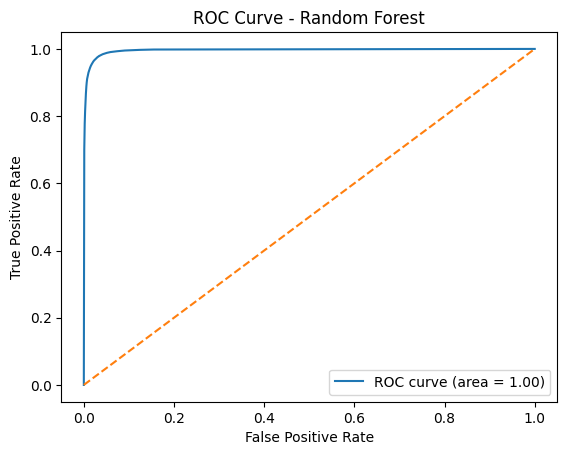

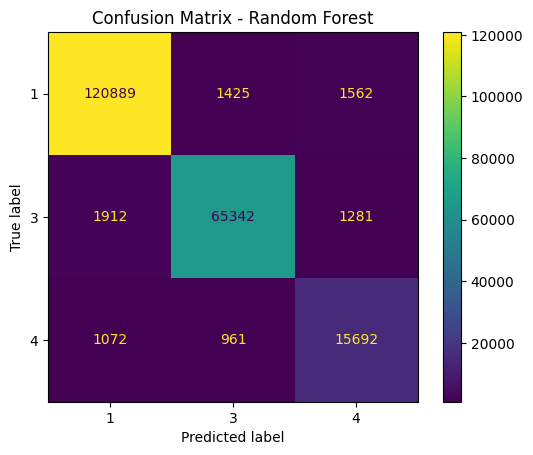

In [28]:
rf_model = RandomForestClassifier(n_jobs=-1, random_state=42)
print("\n🔄 Training: Random Forest")
start = time.time()

rf_model.fit(X_train_smote, y_train_smote)
rf_y_pred = rf_model.predict(X_test)
rf_y_prob = rf_model.predict_proba(X_test)

end = time.time()
rf_acc = accuracy_score(y_test, rf_y_pred)
print(f"✅ Accuracy: {rf_acc:.4f}")
print("📋 Classification Report:\n", classification_report(y_test, rf_y_pred))

# ROC-AUC Curve
pos_class_index = le.transform(['3'])[0]
fpr, tpr, _ = roc_curve(le.transform(y_test), rf_y_prob[:, pos_class_index], pos_label=pos_class_index)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test, rf_y_pred, labels=le.classes_)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()



🔄 Training: XGBoost
✅ Accuracy: 0.9585
📋 Classification Report:
               precision    recall  f1-score   support

           1       0.98      0.97      0.97    123876
           3       0.97      0.95      0.96     68535
           4       0.81      0.91      0.86     17725

    accuracy                           0.96    210136
   macro avg       0.92      0.94      0.93    210136
weighted avg       0.96      0.96      0.96    210136



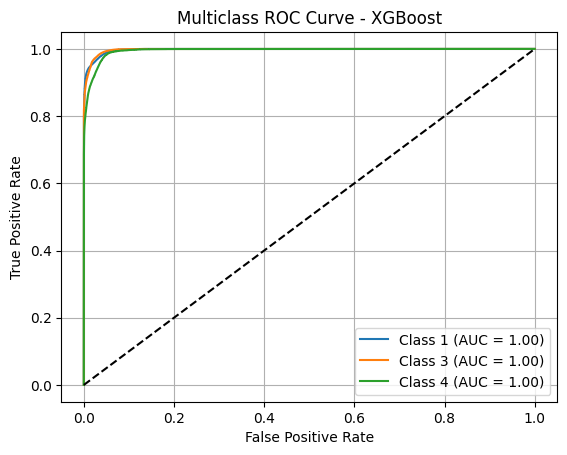

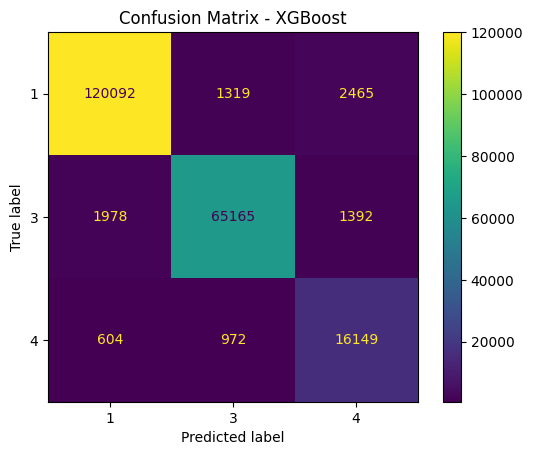

In [29]:
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', n_jobs=-1, random_state=42)
print("\n🔄 Training: XGBoost")
start = time.time()

xgb_model.fit(X_train_smote, y_train_encoded)
xgb_y_pred_encoded = xgb_model.predict(X_test)
xgb_y_prob = xgb_model.predict_proba(X_test)
xgb_y_pred = le.inverse_transform(xgb_y_pred_encoded)

end = time.time()
xgb_acc = accuracy_score(y_test, xgb_y_pred)
print(f"✅ Accuracy: {xgb_acc:.4f}")
print("📋 Classification Report:\n", classification_report(y_test, xgb_y_pred))

# ROC-AUC Curve
y_test_bin = label_binarize(le.transform(y_test), classes=range(len(le.classes_)))
fpr, tpr, roc_auc = {}, {}, {}

for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], xgb_y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure()
for i in range(len(le.classes_)):
    plt.plot(fpr[i], tpr[i], label=f"Class {le.classes_[i]} (AUC = {roc_auc[i]:.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.title("Multiclass ROC Curve - XGBoost")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid()
plt.show()

cm = confusion_matrix(y_test, xgb_y_pred, labels=le.classes_)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot()
plt.title("Confusion Matrix - XGBoost")
plt.show()



🔄 Training: LightGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.563676 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 36042
[LightGBM] [Info] Number of data points in the train set: 867126, number of used features: 175
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
✅ Accuracy: 0.9582
📋 Classification Report:
               precision    recall  f1-score   support

           1       0.98      0.97      0.97    123876
           3       0.96      0.96      0.96     68535
           4       0.81      0.91      0.86     17725

    accuracy                           0.96    210136
   macro avg       0.92      0.94      0.93    210136
weighted avg       0.96      0.96      0.96    210136

[LightGBM] [Info] Number of positive: 289042, number of negative: 578084
[LightGBM] [Info] Auto-ch

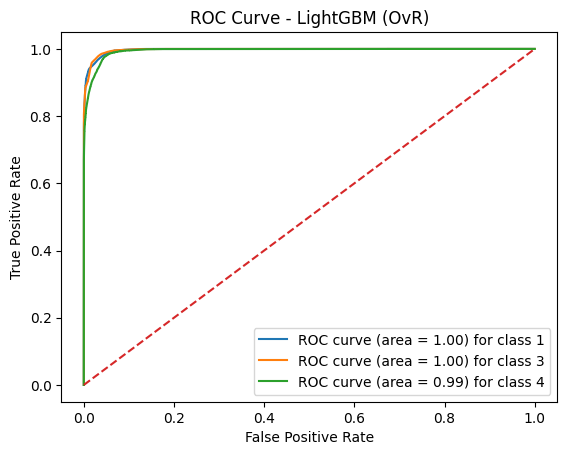

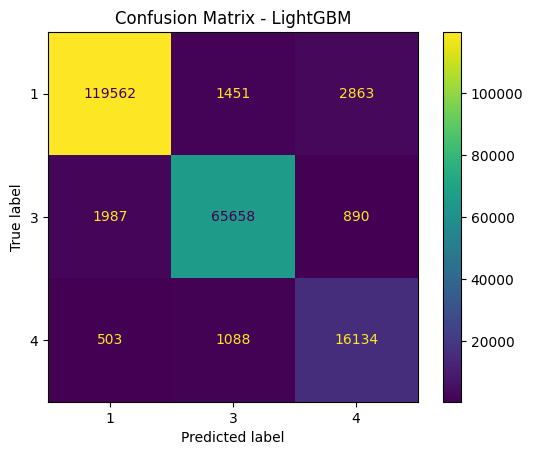

In [30]:
lgb_model = LGBMClassifier(n_jobs=-1, random_state=42)
print("\n🔄 Training: LightGBM")
start = time.time()

lgb_model.fit(X_train_smote, y_train_encoded)
lgb_y_pred_encoded = lgb_model.predict(X_test)
lgb_y_prob = lgb_model.predict_proba(X_test)
lgb_y_pred = le.inverse_transform(lgb_y_pred_encoded)

end = time.time()
lgb_acc = accuracy_score(y_test, lgb_y_pred)
print(f"✅ Accuracy: {lgb_acc:.4f}")
print("📋 Classification Report:\n", classification_report(y_test, lgb_y_pred))

y_test_bin = label_binarize(y_test, classes=le.classes_)
classifier = OneVsRestClassifier(lgb_model)
lgb_y_score = classifier.fit(X_train_smote, y_train_encoded).predict_proba(X_test)

fpr, tpr, roc_auc = {}, {}, {}
n_classes = y_test_bin.shape[1]

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], lgb_y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure()
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC curve (area = {roc_auc[i]:.2f}) for class {le.classes_[i]}')

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - LightGBM (OvR)")
plt.legend(loc="lower right")
plt.show()

cm = confusion_matrix(y_test, lgb_y_pred, labels=le.classes_)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot()
plt.title("Confusion Matrix - LightGBM")
plt.show()



🔄 Training: Naive Bayes
✅ Accuracy: 0.5326
📋 Classification Report:
               precision    recall  f1-score   support

           1       0.94      0.36      0.52    123876
           3       0.44      0.84      0.58     68535
           4       0.31      0.54      0.40     17725

    accuracy                           0.53    210136
   macro avg       0.56      0.58      0.50    210136
weighted avg       0.72      0.53      0.53    210136



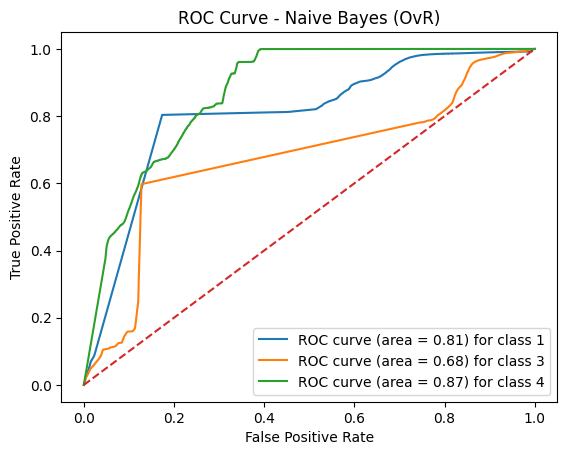

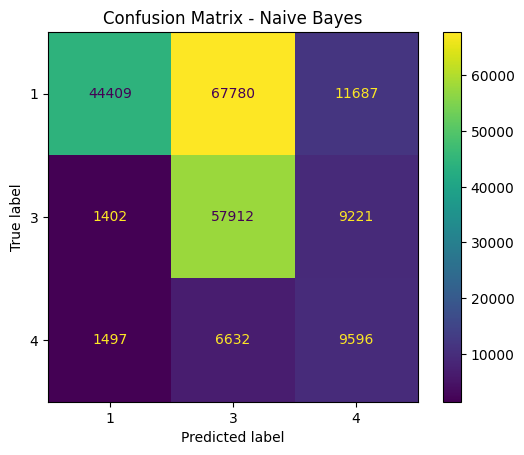

In [31]:
nb_model = GaussianNB()
print("\n🔄 Training: Naive Bayes")
start = time.time()

nb_model.fit(X_train_smote, y_train_smote)
nb_y_pred = nb_model.predict(X_test)
nb_y_prob = nb_model.predict_proba(X_test)

end = time.time()
nb_acc = accuracy_score(y_test, nb_y_pred)
print(f"✅ Accuracy: {nb_acc:.4f}")
print("📋 Classification Report:\n", classification_report(y_test, nb_y_pred))

y_test_bin = label_binarize(y_test, classes=le.classes_)
classifier = OneVsRestClassifier(nb_model)
nb_y_score = classifier.fit(X_train_smote, y_train_smote).predict_proba(X_test)

fpr, tpr, roc_auc = {}, {}, {}
n_classes = y_test_bin.shape[1]
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], nb_y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure()
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC curve (area = {roc_auc[i]:.2f}) for class {le.classes_[i]}')

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes (OvR)")
plt.legend(loc="lower right")
plt.show()

cm = confusion_matrix(y_test, nb_y_pred, labels=le.classes_)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot()
plt.title("Confusion Matrix - Naive Bayes")
plt.show()


In [ ]:
# === MLP Model ===
num_classes = len(le.classes_)

mlp_model = Sequential([
    Input(shape=(X_train_np.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax')
])

mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mlp_model.fit(
    X_train_np, y_train_np,
    validation_split=0.1,
    epochs=20,
    batch_size=256,
    verbose=1
)

# === MLP Predictions ===
mlp_pred_probs = mlp_model.predict(X_test_np)
mlp_pred = np.argmax(mlp_pred_probs, axis=1)

# === MLP Evaluation ===
mlp_acc = accuracy_score(y_test_np, mlp_pred)
print("\n✅ MLP Accuracy:  {:.4f}".format(mlp_acc))
print("\n📋 MLP Classification Report:\n", classification_report(y_test_np, mlp_pred))

# === MLP ROC-AUC Curve ===
y_test_bin = label_binarize(y_test_np, classes=range(num_classes))
fpr = dict(); tpr = dict(); roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], mlp_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure()
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {le.classes_[i]} (AUC = {roc_auc[i]:.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.title("Multiclass ROC Curve - MLP")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid()
plt.show()

# === MLP Confusion Matrix ===
cm = confusion_matrix(y_test_np, mlp_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - MLP")
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


Epoch 1/20
3049/3049 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.4036 - loss: 654.5682 - val_accuracy: 0.0000e+00 - val_loss: 1.3308
Epoch 2/20
3049/3049 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - accuracy: 0.4198 - loss: 1.0854 - val_accuracy: 0.0000e+00 - val_loss: 1.2853
Epoch 3/20
3049/3049 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - accuracy: 0.4307 - loss: 1.0470 - val_accuracy: 0.0000e+00 - val_loss: 1.2875
Epoch 4/20
 373/3049 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.4282 - loss: 1.0583

In [ ]:
strategy = tf.distribute.MirroredStrategy()

input_shape = X_train_np.shape[1]
num_classes = len(np.unique(y_train_np))

def resnet_block(x, units, dropout_rate=0.3):
    shortcut = x
    x = Dense(units)(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = Dropout(dropout_rate)(x)

    x = Dense(units)(x)
    x = BatchNormalization()(x)
    x = Add()([x, shortcut])
    x = ReLU()(x)
    x = Dropout(dropout_rate)(x)
    return x

with strategy.scope():
    inputs = Input(shape=(input_shape,))
    x = Dense(128)(inputs)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    x = resnet_block(x, 128)
    x = resnet_block(x, 128)

    x = Dense(64)(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = Dropout(0.3)(x)

    outputs = Dense(num_classes, activation='softmax')(x)

    resnet_model = Model(inputs, outputs)
    resnet_model.compile(optimizer=Adam(1e-3),
                         loss='sparse_categorical_crossentropy',
                         metrics=['accuracy'])

history_resnet = resnet_model.fit(
    X_train_np, y_train_np,
    validation_data=(X_test_np, y_test_np),
    epochs=20,
    batch_size=512,
    verbose=1
)

resnet_pred_probs = resnet_model.predict(X_test_np)
resnet_pred = np.argmax(resnet_pred_probs, axis=1)

resnet_acc = accuracy_score(y_test_np, resnet_pred)
print(f"\n✅ ResNet MLP Accuracy: {resnet_acc:.4f}")
print("\n📋 ResNet MLP Classification Report:\n", classification_report(y_test_np, resnet_pred, digits=4))

cm = confusion_matrix(y_test_np, resnet_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("🧩 Confusion Matrix - ResNet MLP")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# === ResNet ROC-AUC ===
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], resnet_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure()
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {le.classes_[i]} (AUC = {roc_auc[i]:.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.title("📈 Multiclass ROC Curve - ResNet MLP")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid()
plt.show()


In [ ]:
# === Label Encoding and Scaling ===
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train_smote)
y_test_encoded = le.transform(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

# === Reshape for LSTM ===
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

# === Build LSTM ===
lstm_model = tf.keras.Sequential([
    tf.keras.layers.LSTM(128, input_shape=(1, X_train_lstm.shape[2]), return_sequences=False),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(np.unique(y_train_encoded)), activation='softmax')
])

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# === Callbacks ===
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5, min_lr=1e-6)

# === Training ===
history_lstm = lstm_model.fit(
    X_train_lstm, y_train_encoded,
    epochs=20,
    batch_size=256,
    validation_data=(X_test_lstm, y_test_encoded),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# === Prediction ===
lstm_pred_probs = lstm_model.predict(X_test_lstm)
lstm_pred = np.argmax(lstm_pred_probs, axis=1)

print("✅ LSTM Accuracy Score:", accuracy_score(y_test_encoded, lstm_pred))
print("\n📋 LSTM Classification Report:")
print(classification_report(y_test_encoded, lstm_pred, target_names=[str(c) for c in le.classes_]))

# === Confusion Matrix ===
cm = confusion_matrix(y_test_encoded, lstm_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', xticks_rotation='vertical')
plt.title("Confusion Matrix - LSTM")
plt.show()


In [26]:
import os
import joblib
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tensorflow.keras.models import save_model
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.naive_bayes import GaussianNB
import numpy as np


# Create directory to store best model
os.makedirs("saved_models", exist_ok=True)

# Assuming X_train_smote, y_train_smote, X_test, y_test,
# X_train_np, y_train_np, X_test_np, y_test_np,
# X_train_lstm, y_train_encoded, X_test_lstm, y_test_encoded
# are defined in previous cells

# 1. Train and get predictions for classical models
rf_model = RandomForestClassifier(n_jobs=-1, random_state=42).fit(X_train_smote, y_train_smote)
rf_pred = rf_model.predict(X_test)
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', n_jobs=-1, random_state=42).fit(X_train_smote, y_train_encoded)
xgb_pred = xgb_model.predict(X_test)
lgb_model = LGBMClassifier(n_jobs=-1, random_state=42).fit(X_train_smote, y_train_encoded)
lgb_pred = lgb_model.predict(X_test)
nb_model = GaussianNB().fit(X_train_smote, y_train_smote)
nb_pred = nb_model.predict(X_test)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.247934 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 36042
[LightGBM] [Info] Number of data points in the train set: 867126, number of used features: 175
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612


In [27]:
# 2. Get predictions for deep learning models (assuming models are already trained)
mlp_pred = np.argmax(mlp_model.predict(X_test_np), axis=1)
# Use the correct ResNet model variable (assuming it's named 'resnet_model')
resnet_pred = np.argmax(resnet_model.predict(X_test_np), axis=1) # Changed 'model' to 'resnet_model'
lstm_pred = np.argmax(lstm_model.predict(X_test_lstm), axis=1)   # Changed 'model' to 'lstm_model'



6567/6567 ━━━━━━━━━━━━━━━━━━━━ 7s 991us/step


NameError: name 'resnet_model' is not defined

In [ ]:
# 3. Store models and predictions in a dictionary

models = {
    "RandomForest": {"model": rf_model, "y_pred": rf_pred},
    "XGBoost": {"model": xgb_model, "y_pred": xgb_pred},
    "LightGBM": {"model": lgb_model, "y_pred": lgb_pred},
    "NaiveBayes": {"model": nb_model, "y_pred": nb_pred},
    "MLP": {"model": mlp_model, "y_pred": mlp_pred},
    "ResNetMLP": {"model": resnet_model, "y_pred": resnet_pred}, # Changed 'model' to 'resnet_model'
    "LSTM": {"model": lstm_model, "y_pred": lstm_pred}          # Changed 'model' to 'lstm_model'
}

In [ ]:
# 4. Evaluate and select the best model
y_true = y_test
best_model_name = None
best_model_obj = None
best_f1 = 0
best_accuracy = 0

for name, data in models.items():
    y_pred = data["y_pred"]
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f"Model: {name}")
    print("Accuracy:", accuracy)
    print("F1 Score:", f1)
    print("Classification Report:\n", classification_report(y_true, y_pred))
    print("-----")

    if f1 > best_f1 or (f1 == best_f1 and accuracy > best_accuracy):
        best_model_name = name
        best_model_obj = data["model"]
        best_f1 = f1
        best_accuracy = accuracy


In [ ]:
# 5. Save the best model
print(f"\n✅ Best model is: {best_model_name} (F1: {best_f1}, Accuracy: {best_accuracy})")

if best_model_name in ["RandomForest", "XGBoost", "LightGBM", "NaiveBayes"]:
    joblib.dump(best_model_obj, f"saved_models/{best_model_name}_best_model.pkl")
    print(f"✅ Saved {best_model_name} model at saved_models/{best_model_name}_best_model.pkl")
else:
    save_model(best_model_obj, f"saved_models/{best_model_name}_best_model")
    print(f"✅ Saved {best_model_name} Keras model at saved_models/{best_model_name}_best_model/")